In [4]:
# import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from pandas_datareader import data as wb
from scipy import stats
import statsmodels.api as sm

In [5]:
# List of tickers
tickers = ['D05.SI', '1155.KL', 'BMRI.JK', 'BBL.BK', 'BDOUY', 'VNM']
# Download 'Close' prices for all tickers at once
data = yf.download(tickers, start='2020-01-01', end='2026-01-01')['Close']

C:\Users\USER\AppData\Local\Temp\ipykernel_17924\3509744919.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start='2020-01-01', end='2026-01-01')['Close']
[*********************100%***********************]  6 of 6 completed


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1562 entries, 2020-01-02 to 2025-12-31
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   1155.KL  1470 non-null   float64
 1   BBL.BK   1453 non-null   float64
 2   BDOUY    1508 non-null   float64
 3   BMRI.JK  1447 non-null   float64
 4   D05.SI   1508 non-null   float64
 5   VNM      1508 non-null   float64
dtypes: float64(6)
memory usage: 85.4 KB


In [7]:
data.head()

Ticker,1155.KL,BBL.BK,BDOUY,BMRI.JK,D05.SI,VNM
Date,,,,,,
2020-01-02,5.524510,120.909309,22.090994,2482.786621,16.699354,15.115705
2020-01-03,5.524510,118.690781,22.632479,2474.778076,16.629000,14.957670
2020-01-06,5.461373,115.363029,22.683702,2434.732910,16.539463,14.911188
2020-01-07,5.461373,115.732742,21.878790,2434.732910,16.660986,14.883300
2020-01-08,5.391922,113.144463,22.551985,2402.697021,16.456316,14.743855


In [8]:
data.tail

<bound method NDFrame.tail of Ticker       1155.KL      BBL.BK      BDOUY      BMRI.JK     D05.SI        VNM
Date                                                                          
2020-01-02  5.524510  120.909309  22.090994  2482.786621  16.699354  15.115705
2020-01-03  5.524510  118.690781  22.632479  2474.778076  16.629000  14.957670
2020-01-06  5.461373  115.363029  22.683702  2434.732910  16.539463  14.911188
2020-01-07  5.461373  115.732742  21.878790  2434.732910  16.660986  14.883300
2020-01-08  5.391922  113.144463  22.551985  2402.697021  16.456316  14.743855
...              ...         ...        ...          ...        ...        ...
2025-12-25       NaN  158.314026        NaN          NaN        NaN        NaN
2025-12-26  9.808976  159.256378  22.553883          NaN  54.093357  18.400000
2025-12-29  9.846703  158.785202  22.203758  4500.009766  54.064495  18.920000
2025-12-30  9.903294  159.727539  22.495527  4522.177246  54.353096  19.010000
2025-12-31  9.884430  

In [9]:
data.iloc[0]

Ticker
1155.KL       5.524510
BBL.BK      120.909309
BDOUY        22.090994
BMRI.JK    2482.786621
D05.SI       16.699354
VNM          15.115705
Name: 2020-01-02 00:00:00, dtype: float64

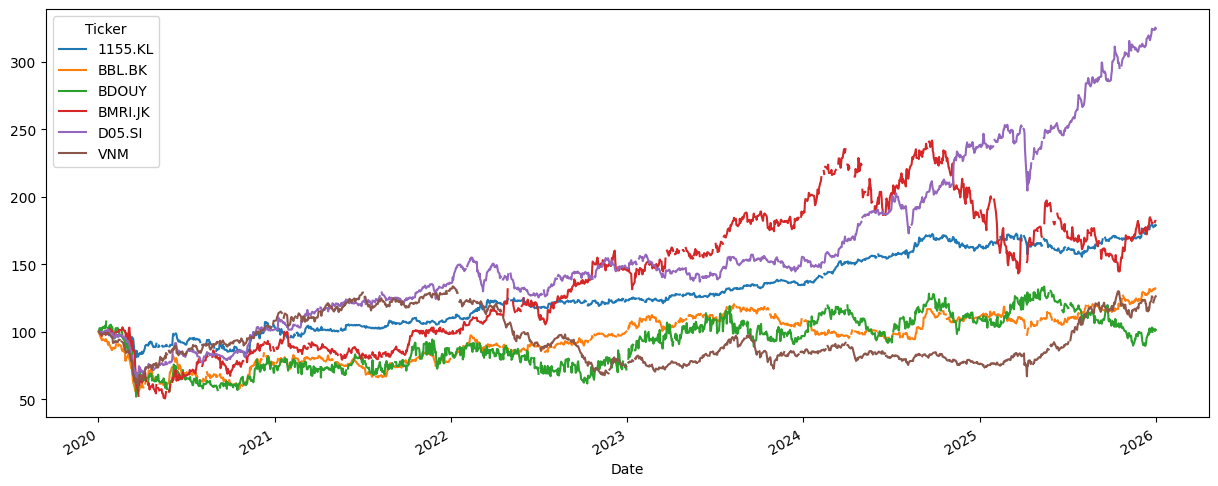

In [10]:
(data / data.iloc[0] * 100).plot(figsize = (15,6))
plt.show()

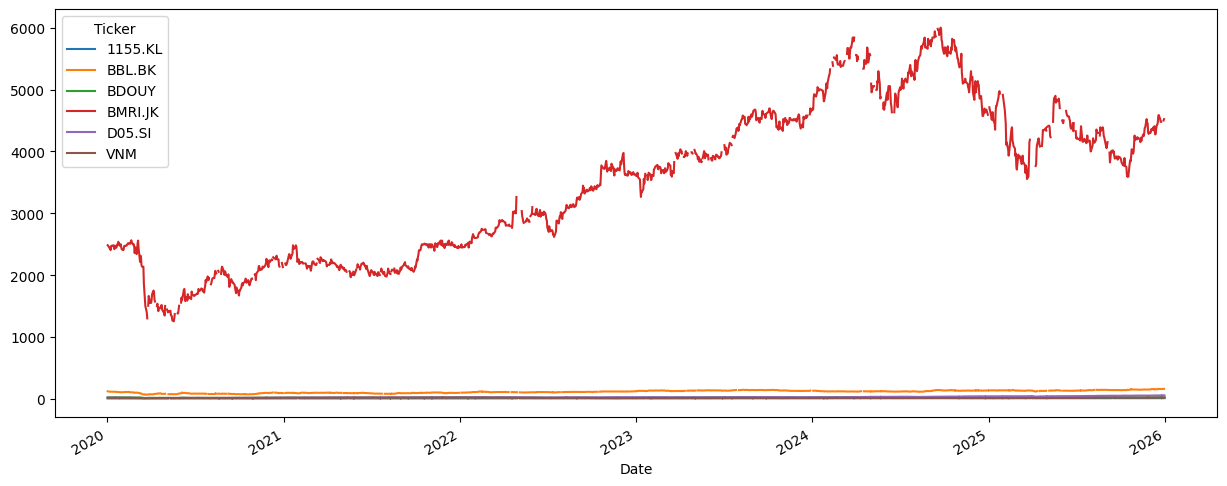

In [11]:
data.plot(figsize=(15,6))
plt.show()

In [12]:
# calculating the return
returns = (data / data.shift(1)) - 1
returns.head()

Ticker,1155.KL,BBL.BK,BDOUY,BMRI.JK,D05.SI,VNM
Date,,,,,,
2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.000000,-0.018349,0.024512,-0.003226,-0.004213,-0.010455
2020-01-06,-0.011428,-0.028037,0.002263,-0.016181,-0.005384,-0.003108
2020-01-07,0.000000,0.003205,-0.035484,0.000000,0.007347,-0.001870
2020-01-08,-0.012717,-0.022364,0.030769,-0.013158,-0.012284,-0.009369


In [13]:
weights = np.array([0.25, 0.25, 0.25, 0.25, 0.25, 0.25])

In [14]:
np.dot(returns, weights)

array([        nan, -0.0029327 , -0.01546889, ...,         nan,
        0.00996086,         nan], shape=(1562,))

In [15]:
annual_returns = returns.mean() *250
annual_returns

Ticker
1155.KL    0.121142
BBL.BK     0.077029
BDOUY      0.128968
BMRI.JK    0.144318
D05.SI     0.190696
VNM        0.078165
dtype: float64

In [16]:
np.dot(annual_returns, weights)

np.float64(0.18507968735747074)

In [17]:
pfolio_1 = str(round(np.dot(annual_returns, weights),5)*100) + ' %'
print(pfolio_1)

18.508 %


In [18]:
weights_2 = np.array([0.4, 0.4, 0.15, 0.05, 0.20, 0.20])

In [19]:
pfolio_2 = str(round(np.dot(annual_returns, weights_2),5)*100) +' %'
print(pfolio_2)

15.959999999999999 %


In [20]:
# return of indices
ind_returns =(data / data.shift(1))-1
ind_returns.tail()

Ticker,1155.KL,BBL.BK,BDOUY,BMRI.JK,D05.SI,VNM
Date,,,,,,
2025-12-25,NaN,0.002985,NaN,NaN,NaN,NaN
2025-12-26,NaN,0.005952,NaN,NaN,NaN,NaN
2025-12-29,0.003846,-0.002959,-0.015524,NaN,-0.000534,0.028261
2025-12-30,0.005747,0.005935,0.013141,0.004926,0.005338,0.004757
2025-12-31,-0.001905,NaN,-0.005620,NaN,-0.002478,0.003682


In [21]:
annual_ind_returns = ind_returns.mean() * 250
annual_ind_returns

Ticker
1155.KL    0.121142
BBL.BK     0.077029
BDOUY      0.128968
BMRI.JK    0.144318
D05.SI     0.190696
VNM        0.078165
dtype: float64

In [22]:
sec_returns = np.log(data/ data.shift(1))

In [23]:
sec_returns

Ticker,1155.KL,BBL.BK,BDOUY,BMRI.JK,D05.SI,VNM
Date,,,,,,
2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.000000,-0.018519,0.024216,-0.003231,-0.004222,-0.010510
2020-01-06,-0.011494,-0.028438,0.002261,-0.016314,-0.005399,-0.003112
2020-01-07,0.000000,0.003200,-0.036129,0.000000,0.007321,-0.001872
2020-01-08,-0.012798,-0.022618,0.030305,-0.013245,-0.012360,-0.009413
...,...,...,...,...,...,...
2025-12-25,NaN,0.002981,NaN,NaN,NaN,NaN
2025-12-26,NaN,0.005935,NaN,NaN,NaN,NaN
2025-12-29,0.003839,-0.002963,-0.015646,NaN,-0.000534,0.027869


In [24]:
sec_returns[['1155.KL', 'BBL.BK','BDOUY','BMRI.JK','D05.SI','VNM']].mean() * 250

Ticker
1155.KL    0.109841
BBL.BK     0.046190
BDOUY     -0.047502
BMRI.JK    0.089640
D05.SI     0.171119
VNM        0.046042
dtype: float64

In [25]:
sec_returns[['1155.KL', 'BBL.BK','BDOUY','BMRI.JK','D05.SI','VNM']].std()

Ticker
1155.KL    0.009512
BBL.BK     0.015725
BDOUY      0.037624
BMRI.JK    0.020919
D05.SI     0.012495
VNM        0.016060
dtype: float64

In [26]:
sec_returns[['1155.KL', 'BBL.BK','BDOUY','BMRI.JK','D05.SI','VNM']].std() * 250 ** 0.5

Ticker
1155.KL    0.150392
BBL.BK     0.248628
BDOUY      0.594883
BMRI.JK    0.330759
D05.SI     0.197570
VNM        0.253937
dtype: float64

In [27]:
KL_var = sec_returns['1155.KL'].var()
print(KL_var)
BK_var = sec_returns['BBL.BK'].var()
print(BK_var)
BDOUY_var = sec_returns['BDOUY'].var()
print(BDOUY_var)
BMRI_var = sec_returns['BMRI.JK'].var()
print(BMRI_var)
D05_var = sec_returns['D05.SI'].var()
print(D05_var)
VNM_var = sec_returns['VNM'].var()
print(VNM_var)

9.047083457886447e-05
0.00024726278713720654
0.0014155445747871898
0.0004376072491261533
0.00015613585802466378
0.00025793516772550464


In [28]:
KLvar_a = sec_returns['1155.KL'].var()*250
print(KLvar_a)
BKvar_a = sec_returns['BBL.BK'].var()*250
print(BKvar_a)
BDOUYvar_a = sec_returns['BDOUY'].var()*250
print(BDOUYvar_a)
JKvar_a = sec_returns['BMRI.JK'].var()*250
print(JKvar_a)
SIvar_a = sec_returns['D05.SI'].var()*250
print(SIvar_a)
VNMvar_a = sec_returns['VNM'].var()*250
print(VNMvar_a)

0.022617708644716118
0.061815696784301634
0.35388614369679744
0.10940181228153834
0.03903396450616595
0.06448379193137616


In [29]:
cov_matrix = sec_returns.cov()
cov_matrix

Ticker,1155.KL,BBL.BK,BDOUY,BMRI.JK,D05.SI,VNM
Ticker,,,,,,
1155.KL,0.000090,0.000049,0.000054,0.000028,0.000043,0.000021
BBL.BK,0.000049,0.000247,0.000087,0.000060,0.000067,0.000043
BDOUY,0.000054,0.000087,0.001416,0.000061,0.000057,0.000064
BMRI.JK,0.000028,0.000060,0.000061,0.000438,0.000054,0.000027
D05.SI,0.000043,0.000067,0.000057,0.000054,0.000156,0.000036
VNM,0.000021,0.000043,0.000064,0.000027,0.000036,0.000258


In [30]:
cov_matrix = sec_returns.cov() * 250
cov_matrix

Ticker,1155.KL,BBL.BK,BDOUY,BMRI.JK,D05.SI,VNM
Ticker,,,,,,
1155.KL,0.022618,0.012244,0.013562,0.006877,0.010857,0.005317
BBL.BK,0.012244,0.061816,0.021763,0.014898,0.016850,0.010866
BDOUY,0.013562,0.021763,0.353886,0.015170,0.014327,0.015955
BMRI.JK,0.006877,0.014898,0.015170,0.109402,0.013442,0.006841
D05.SI,0.010857,0.016850,0.014327,0.013442,0.039034,0.009086
VNM,0.005317,0.010866,0.015955,0.006841,0.009086,0.064484


In [31]:
cov_matrix = sec_returns.corr()
cov_matrix

Ticker,1155.KL,BBL.BK,BDOUY,BMRI.JK,D05.SI,VNM
Ticker,,,,,,
1155.KL,1.000000,0.326771,0.149487,0.137225,0.357815,0.136506
BBL.BK,0.326771,1.000000,0.144380,0.174318,0.342378,0.170693
BDOUY,0.149487,0.144380,1.000000,0.075573,0.119578,0.105615
BMRI.JK,0.137225,0.174318,0.075573,1.000000,0.207966,0.083334
D05.SI,0.357815,0.342378,0.119578,0.207966,1.000000,0.177955
VNM,0.136506,0.170693,0.105615,0.083334,0.177955,1.000000


In [32]:
# calculating portfolio risk
weights = np.array([0.5,0.5,0.5,0.5,0.5,0.5])

In [33]:
# portfolio variance
pfolio_var = np.dot(weights.T, np.dot(sec_returns.cov() *250, weights))
pfolio_var

np.float64(0.25683660855365514)

In [34]:
# portfolio volatility
pfolio_vol = (np.dot(weights.T, np.dot(sec_returns.cov()*250, weights)))**0.5
pfolio_vol

np.float64(0.5067904976947132)

In [35]:
print (str(round(pfolio_vol, 5)*100) + '%')

50.678999999999995%


In [36]:
cov = sec_returns.cov() * 250
cov

Ticker,1155.KL,BBL.BK,BDOUY,BMRI.JK,D05.SI,VNM
Ticker,,,,,,
1155.KL,0.022618,0.012244,0.013562,0.006877,0.010857,0.005317
BBL.BK,0.012244,0.061816,0.021763,0.014898,0.016850,0.010866
BDOUY,0.013562,0.021763,0.353886,0.015170,0.014327,0.015955
BMRI.JK,0.006877,0.014898,0.015170,0.109402,0.013442,0.006841
D05.SI,0.010857,0.016850,0.014327,0.013442,0.039034,0.009086
VNM,0.005317,0.010866,0.015955,0.006841,0.009086,0.064484


In [37]:
cov_with_market = cov.iloc[0,1]
cov_with_market

np.float64(0.012243881400178874)

In [38]:
market_var1 = sec_returns['1155.KL'].var()*250
market_var1

np.float64(0.022617708644716118)

In [39]:
market_var2 = sec_returns['BBL.BK'].var()*250
market_var2

np.float64(0.061815696784301634)

In [40]:
market_var3 = sec_returns['BDOUY'].var()*250
market_var3

np.float64(0.35388614369679744)

In [41]:
market_var4 = sec_returns['BMRI.JK'].var()*250
market_var4

np.float64(0.10940181228153834)

In [42]:
market_var5 = sec_returns['D05.SI'].var()*250
market_var5

np.float64(0.03903396450616595)

In [43]:
market_var6 = sec_returns['VNM'].var()*250
market_var6

np.float64(0.06448379193137616)

In [44]:
KL_beta = cov_with_market / market_var1
print("1155.KL beta: ",KL_beta)
BK_beta = cov_with_market / market_var2
print("BBL.BK beta: ",BK_beta)
BDOUY_beta = cov_with_market / market_var3
print("BDOUY beta: ",BDOUY_beta)
JK_beta = cov_with_market / market_var4
print("JK beta: ",JK_beta)
SI_beta = cov_with_market / market_var5
print("D05.SI beta: ",SI_beta)
VNM_beta = cov_with_market / market_var6
print("VNM beta: ",VNM_beta)

1155.KL beta:  0.5413404864528244
BBL.BK beta:  0.19807074961724383
BDOUY beta:  0.034598363395287914
JK beta:  0.11191662317869154
D05.SI beta:  0.31367250431979016
VNM beta:  0.18987533197813258


In [45]:
#CAPM 
KL_er = 0.025+KL_beta *0.05
print(KL_er)
BK_er =  0.025+BK_beta *0.05
print(BK_er)
BDOUY_er =  0.025+BDOUY_beta *0.05
print(BDOUY_er)
JK_er =  0.025+JK_beta *0.05
print(JK_er)
SI_er =  0.025+SI_beta *0.05
print(SI_er)
VNM_er =  0.025+VNM_beta *0.05
print(VNM_er)

0.05206702432264122
0.034903537480862196
0.026729918169764395
0.030595831158934578
0.040683625215989505
0.03449376659890663


In [46]:
# sharpe ratio
Sharpe1 = (KL_er - 0.025)/(sec_returns['1155.KL'].std()*250**0.5)
print(Sharpe1)
Sharpe2 = (BK_er - 0.025)/(sec_returns['BBL.BK'].std()*250**0.5)
print(Sharpe2)
Sharpe3 = (BDOUY_er - 0.025)/(sec_returns['BDOUY'].std()*250**0.5)
print(Sharpe3)
Sharpe4 = (JK_er - 0.025)/(sec_returns['BMRI.JK'].std()*250**0.5)
print(Sharpe4)
Sharpe5 = (SI_er - 0.025)/(sec_returns['D05.SI'].std()*250**0.5)
print(Sharpe5)
Sharpe6 = (VNM_er - 0.025)/(sec_returns['VNM'].std()*250**0.5)
print(Sharpe6)

0.17997666937288384
0.03983281186504327
0.002907995840934608
0.016918129464950388
0.07938256436339264
0.03738636714338686


In [47]:
# Download data with volume information for regression analysis
import yfinance as yf
tickers = ['D05.SI', '1155.KL', 'BMRI.JK', 'BBL.BK', 'BDOUY', 'VNM']
data_volume = yf.download(tickers, start='2020-01-01', end='2026-01-01', group_by='ticker')
print(f"Data shape: {data_volume.shape}")

C:\Users\USER\AppData\Local\Temp\ipykernel_17924\514108551.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_volume = yf.download(tickers, start='2020-01-01', end='2026-01-01', group_by='ticker')
[*********************100%***********************]  6 of 6 completed

Data shape: (1562, 30)


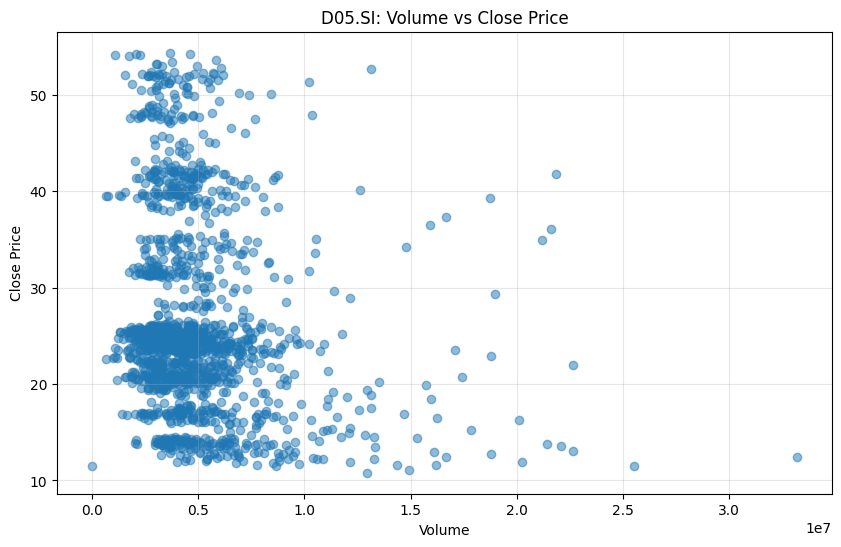

D05.SI Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     52.90
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           5.61e-13
Time:                        11:57:04   Log-Likelihood:                -5603.4
No. Observations:                1508   AIC:                         1.121e+04
Df Residuals:                    1506   BIC:                         1.122e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         29.6973    

In [48]:
# Regression Analysis: D05.SI (DBS Singapore)
ticker_data = data_volume['D05.SI'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('D05.SI: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("D05.SI Regression Summary:")
print(reg.summary())

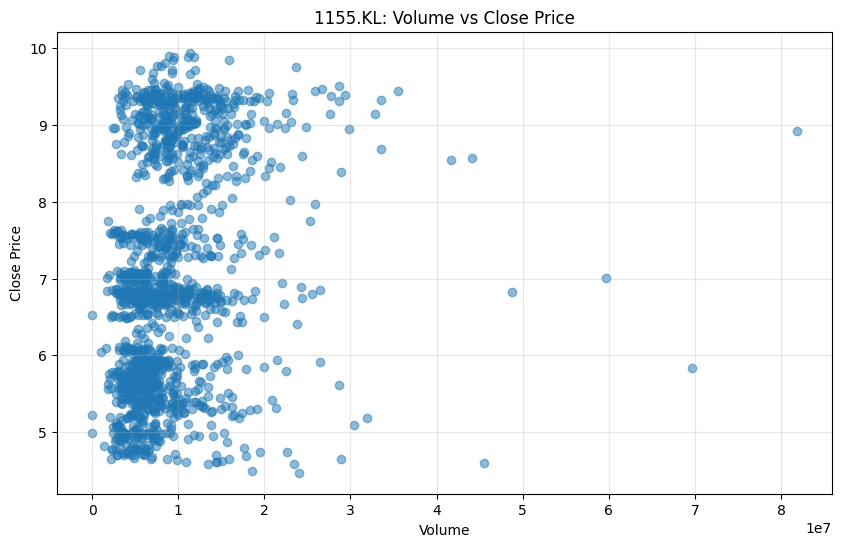

1155.KL Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.063
Model:                            OLS   Adj. R-squared:                  0.062
Method:                 Least Squares   F-statistic:                     98.29
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           1.80e-22
Time:                        11:57:04   Log-Likelihood:                -2635.7
No. Observations:                1470   AIC:                             5275.
Df Residuals:                    1468   BIC:                             5286.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.5111   

In [49]:
# Regression Analysis: 1155.KL (Malaysia)
ticker_data = data_volume['1155.KL'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('1155.KL: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("1155.KL Regression Summary:")
print(reg.summary())

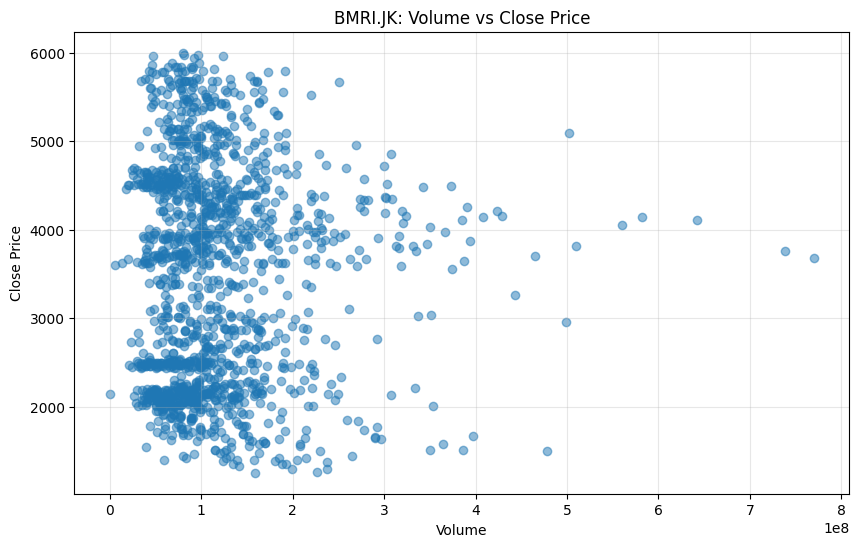

BMRI.JK Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                   0.07984
Date:                Sun, 18 Oct 2026   Prob (F-statistic):              0.778
Time:                        11:57:05   Log-Likelihood:                -12343.
No. Observations:                1447   AIC:                         2.469e+04
Df Residuals:                    1445   BIC:                         2.470e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3486.9524   

In [50]:
# Regression Analysis: BMRI.JK (Indonesia)
ticker_data = data_volume['BMRI.JK'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('BMRI.JK: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("BMRI.JK Regression Summary:")
print(reg.summary())

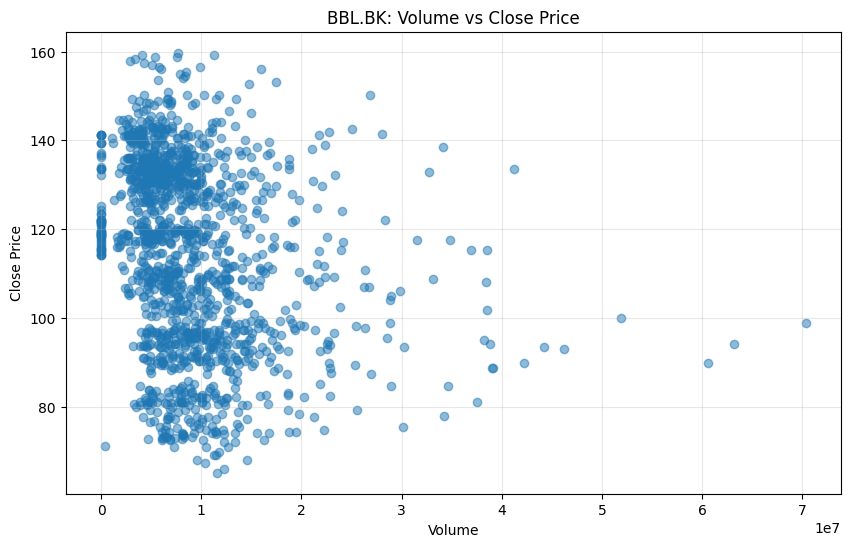

BBL.BK Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.071
Model:                            OLS   Adj. R-squared:                  0.070
Method:                 Least Squares   F-statistic:                     110.1
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           7.07e-25
Time:                        11:57:05   Log-Likelihood:                -6442.3
No. Observations:                1453   AIC:                         1.289e+04
Df Residuals:                    1451   BIC:                         1.290e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        121.7650    

In [51]:
# Regression Analysis: BBL.BK (Thailand)
ticker_data = data_volume['BBL.BK'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('BBL.BK: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("BBL.BK Regression Summary:")
print(reg.summary())

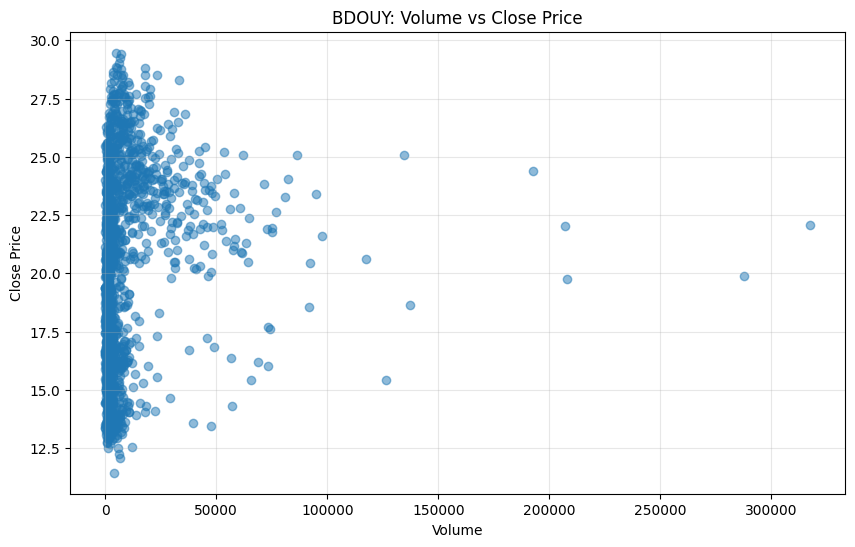

BDOUY Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.027
Method:                 Least Squares   F-statistic:                     42.45
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           9.88e-11
Time:                        11:57:05   Log-Likelihood:                -4269.8
No. Observations:                1508   AIC:                             8544.
Df Residuals:                    1506   BIC:                             8554.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         19.8321     

In [52]:
# Regression Analysis: BDOUY (Philippines)
ticker_data = data_volume['BDOUY'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('BDOUY: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("BDOUY Regression Summary:")
print(reg.summary())

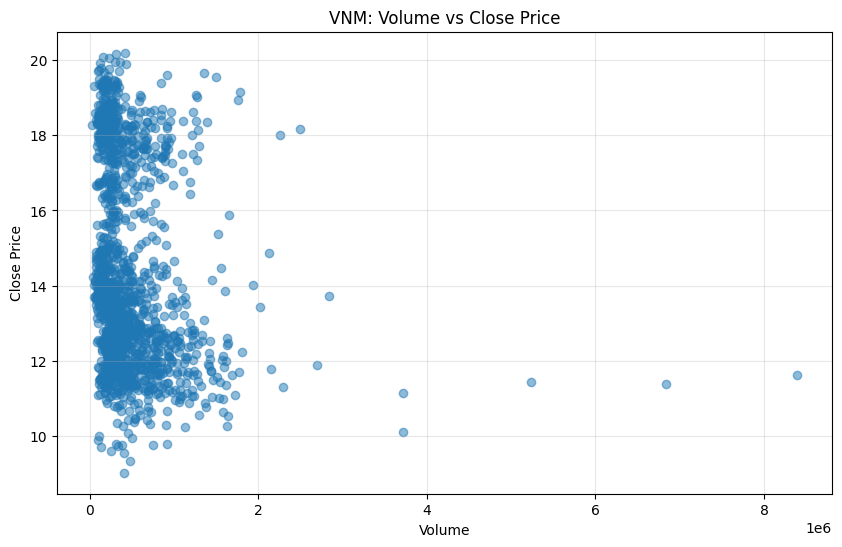

VNM Regression Summary:
                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     57.35
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           6.31e-14
Time:                        11:57:06   Log-Likelihood:                -3585.4
No. Observations:                1508   AIC:                             7175.
Df Residuals:                    1506   BIC:                             7185.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         14.8225      0

In [53]:
# Regression Analysis: VNM (Vietnam)
ticker_data = data_volume['VNM'].dropna()
X = ticker_data[['Volume']] 
Y = ticker_data['Close']

plt.figure(figsize=(10, 6))
plt.scatter(X, Y, alpha=0.5)
plt.xlabel('Volume')
plt.ylabel('Close Price')
plt.title('VNM: Volume vs Close Price')
plt.grid(True, alpha=0.3)
plt.show()

# Regression summary
X1 = sm.add_constant(X)
reg = sm.OLS(Y, X1).fit()
print("VNM Regression Summary:")
print(reg.summary())